# Baseline and thumbnail encoders in the WISP simulator: a walkthrough

**Question.** How much of a frame does the tag have to send for a server trained on this room to tell whether a person is present? This covers approach categories 1 (no compression) and 2 (thumbnails). It is also the first experiment run through the simulator (`semwisp/sim.py`), so it doubles as a check of the harness.

**Setup.**
* Tag: `ThumbnailTag` sends a W×H thumbnail of the 160×120 frame with *b* bits per pixel (the top bits of each value). `mean` averages each block; `subsample` keeps the centre pixel of each block. 160×120 at 8 bits is the uncompressed baseline.
* Link: 12-byte EPCs, no losses. Sensor: no added noise.
* Server: a small CNN trained per configuration on what the server receives from `training` + `training_seats` (every 2nd frame), tested on every frame of `test1`–`test3`.
* Metric: ROC AUC (1.0 = every person frame scores above every empty frame, 0.5 = chance). The labels miss some people (see the exploration notebook), so AUC is capped below 1. With about 760 test frames and one training seed per configuration, differences of about 0.01 are noise.

**Findings in brief** (each is shown in a section below).
1. **The first 100× of compression is free.** AUC is 0.990–0.996 from the uncompressed frame (19,200 bytes, 1,920 EPCs) down to a 16×12 thumbnail (192 bytes, 18 EPCs).
2. **One EPC already gets AUC 0.947**, as 8×6 pixels at 2 bits each. The same 12 bytes spent as 4×3 pixels at 8 bits give 0.910.
3. **1-bit pixels are the weak point**, and 2–4 bits are cheap. The fixed mid-gray threshold is the problem, not 1 bit as such.
4. **Averaging beats subsampling**, slightly at 16×12 and above and clearly below.
5. **At one EPC the limit is the code, not the decoder**: about 8% of test frames produce a payload that frames of the other class also produce, mostly a small, distant person whose payload is byte-for-byte the empty room's.
6. **The corrupted-frame flag misses some frames**: two mildly corrupted frames in `test3` cause the largest score excursions at every payload size.

This is the favourable case: about 3,000 labelled frames of the same room for training, no sensor noise, no EPC loss.

Everything below reads cached results from `results/thumbnail_sweep/` (produced by `experiments/thumbnail_sweep.py`); nothing is retrained here.

## 1. Load the results

One file per configuration, holding the score, label and cost counts of every test query.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..').resolve()))
from semwisp import piropo
from semwisp.frames import load_frames
from semwisp.link import Link
from semwisp.sensor import Sensor
from semwisp.sim import Ledger
from semwisp.tag import ThumbnailTag

TEST = ['test1', 'test2', 'test3']
INK, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'text.color': INK, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.titlesize': 10, 'axes.titlelocation': 'left'})

Q, rows = {}, []          # Q[(size, bits, method)] -> per-query dataframe
for f in sorted((piropo.REPO / 'results' / 'thumbnail_sweep').glob('*.npz')):
    with np.load(f) as z:
        m = json.loads(str(z['meta']))
        if m['read_noise'] or m['p_loss']:
            continue
        k = (f"{m['w']}x{m['h']}", m['bits'], m['method'])
        Q[k] = pd.DataFrame({c: z[c] for c in z.files if c != 'meta'})
        rows.append(dict(size=k[0], bits=k[1], method=k[2], bytes=m['n_bytes'], EPCs=int(z['up_epcs'][0]),
                         mcu_ops=int(z['mcu_ops'][0]), ram_bytes=int(z['ram_bytes'][0]), **m['auc']))
df = pd.DataFrame(rows).sort_values(['bytes', 'method', 'bits'], ascending=[False, True, False]).reset_index(drop=True)
frames = load_frames(TEST)
auc_cols = TEST + ['pooled']
x_ = lambda s: s.replace('x', '×')
print(len(df), 'configurations;', {n: int((~frames[n]['bad']).sum()) for n in TEST}, 'usable test frames')

20 configurations; {'test1': 349, 'test2': 140, 'test3': 275} usable test frames


## 2. What the server actually receives

Before any numbers: the same four test frames as the tag would send them at different payload sizes. Each image is decoded from the real payload bytes that went through the simulated tag and link.

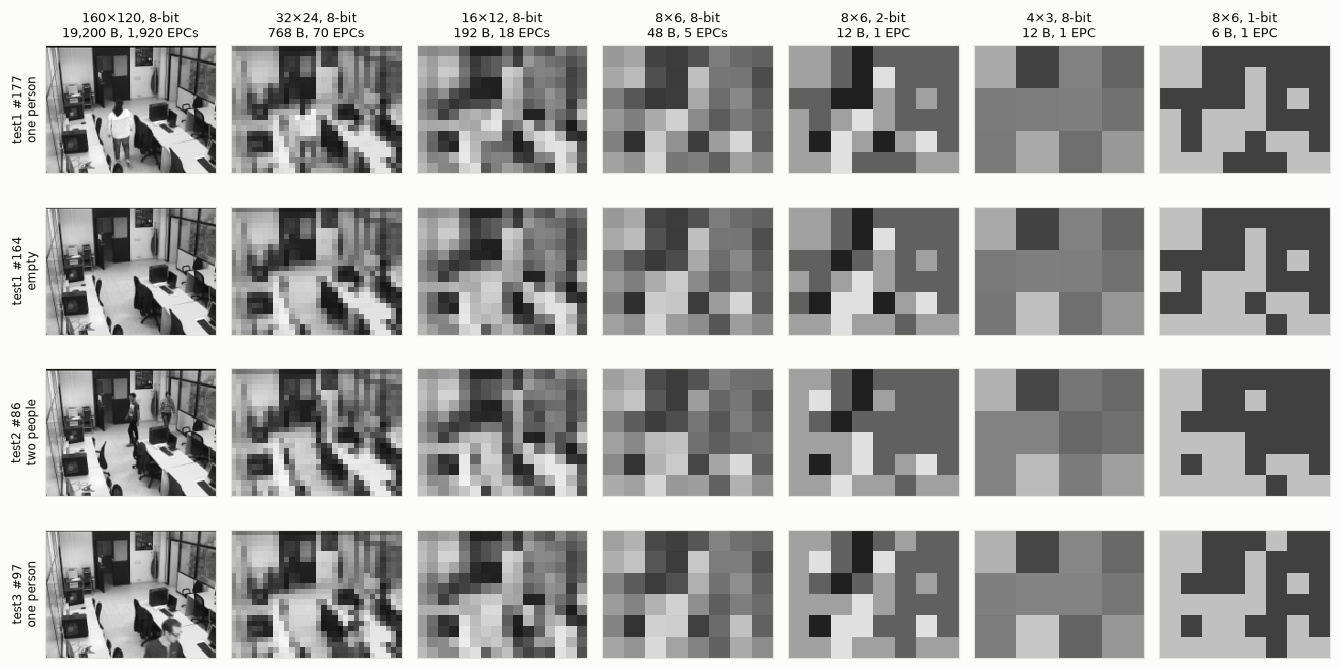

In [3]:
def received(frame, w, h, bits, method='mean'):
    """Run one frame through tag -> link and return what the server unpacks."""
    tag, led = ThumbnailTag(w, h, bits, method), Ledger()
    tag.new_query(Sensor(), frame, led)
    return tag.unpack(Link().uplink(tag.respond(None), led)), led

EXAMPLES = [('test1', 177, 'one person'), ('test1', 164, 'empty'), ('test2', 86, 'two people'), ('test3', 97, 'one person')]

COLS = [(160, 120, 8), (32, 24, 8), (16, 12, 8), (8, 6, 8), (8, 6, 2), (4, 3, 8), (8, 6, 1)]

fig, axes = plt.subplots(len(EXAMPLES), len(COLS), figsize=(13.5, 1.62 * len(EXAMPLES) + 0.6))
for r, (seq, i, what) in enumerate(EXAMPLES):
    for c, (w, h, b) in enumerate(COLS):
        img, led = received(frames[seq]['X'][i], w, h, b)
        ax = axes[r, c]
        ax.imshow(img, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(f"{w}×{h}, {b}-bit\n{led.up_bytes:,} B, {led.up_epcs:,} EPC{'s' if led.up_epcs > 1 else ''}",
                         fontsize=9, loc='center')
        if c == 0:
            ax.set_ylabel(f'{seq} #{i}\n{what}', fontsize=8.5, color=INK)
plt.tight_layout(); plt.show()

**What to notice.**
* At 32×24 and 16×12 a person is still a visible blob to the eye, and these are the sizes where AUC has not dropped at all.
* At 8×6 a person is a change in one or two cells. Compare rows 1 and 2 (same room, with and without a person): the difference is there, but only relative to what the empty room looks like, which is why a decoder trained on this room can use it and a generic detector cannot.
* 8×6 at 2 bits (one EPC) keeps the spatial layout and loses the gray levels; 4×3 at 8 bits (also one EPC) keeps gray levels and loses the layout. The first turns out to be more useful (section 5).
* 8×6 at 1 bit is nearly the same picture in all four rows: with a threshold fixed at mid-gray, most cells never change.
* Row 4 is a hard case at every size: the person is at the bottom edge, partly out of frame.


## 3. AUC against payload size

The main result: pooled AUC over the three test sequences for every configuration.

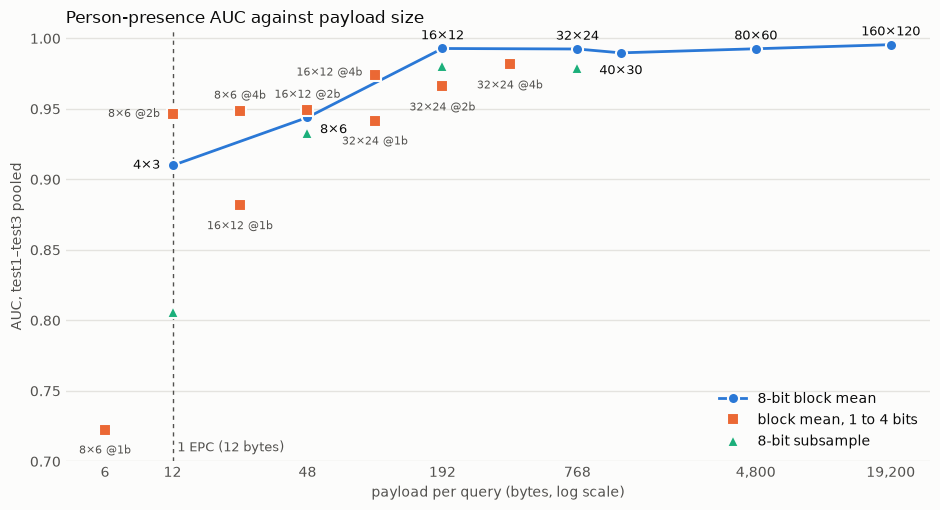

In [4]:
series = [('8-bit block mean', (df.method == 'mean') & (df.bits == 8), BLUE, 'o', '-'),
          ('block mean, 1 to 4 bits', (df.method == 'mean') & (df.bits < 8), ORANGE, 's', ''),
          ('8-bit subsample', (df.method == 'subsample') & (df.bits == 8), AQUA, '^', '')]
# label offsets (points) where the default position would collide
OFFSET = {('4x3', 8): (-9, 0, 'right'), ('8x6', 8): (9, -9, 'left'), ('40x30', 8): (0, -13, 'center'),
          ('8x6', 2): (-9, 0, 'right'), ('8x6', 4): (0, 11, 'center'), ('16x12', 2): (0, 11, 'center'),
          ('16x12', 4): (-9, 2, 'right')}

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.axvline(12, color=MUTED, lw=1, ls=(0, (3, 3)))
ax.text(12.6, 0.705, '1 EPC (12 bytes)', color=MUTED, fontsize=9, va='bottom')
for label, mask, color, marker, ls in series:
    d = df[mask].sort_values('bytes')
    ax.plot(d.bytes, d.pooled, ls=ls, lw=2, marker=marker, ms=8, color=color, mec=SURFACE, mew=1.5, label=label)
    for r in d.itertuples():
        if r.method == 'subsample':
            continue
        dx, dy, ha = OFFSET.get((r.size, r.bits), (0, 9, 'center') if r.bits == 8 else (0, -15, 'center'))
        ax.annotate(x_(r.size) + ('' if r.bits == 8 else f' @{r.bits}b'), (r.bytes, r.pooled), (dx, dy),
                    textcoords='offset points', ha=ha, va='center',
                    fontsize=9 if r.bits == 8 else 8, color=INK if r.bits == 8 else MUTED)
ax.set_xscale('log')
ax.set_xticks([6, 12, 48, 192, 768, 4800, 19200], ['6', '12', '48', '192', '768', '4,800', '19,200'])
ax.minorticks_off()
ax.set_ylim(0.7, 1.005)
ax.set_xlabel('payload per query (bytes, log scale)'); ax.set_ylabel('AUC, test1–test3 pooled')
ax.set_title('Person-presence AUC against payload size', fontsize=12)
ax.grid(axis='y', color=GRID, lw=1); ax.set_axisbelow(True); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

**Reading the chart.**
* The blue line is flat from 19,200 bytes down to 192 bytes (0.990–0.996, within noise), then falls to 0.944 at 48 bytes and 0.910 at 12.
* The orange squares are the same thumbnails with fewer bits per pixel. At 12 bytes, 8×6 at 2 bits (0.947) sits above the blue line's 4×3 (0.910); at 6 bytes, 8×6 at 1 bit collapses to 0.723.
* The green triangles (keep one pixel per block instead of averaging) are below the blue point at the same size every time: by about 0.01 at 192 and 768 bytes and at 48 bytes, and by 0.10 at 12 bytes.
* Nothing here says how low the payload can go with a smarter code. Every point is a uniform grid with uniform quantisation; choosing *which* cells and *which* thresholds for this room is what the adaptive methods are for.


## 4. Per sequence

The pooled number hides differences between sequences. The table has every configuration; the chart shows the 8-bit block-mean ladder.

In [5]:
df[['size', 'bits', 'method', 'bytes', 'EPCs'] + auc_cols].style.format({c: '{:.3f}' for c in auc_cols} | {'bytes': '{:,}', 'EPCs': '{:,}'}) \
  .background_gradient(cmap='Blues', vmin=0.5, vmax=1.0, subset=auc_cols).hide(axis='index')

size,bits,method,bytes,EPCs,test1,test2,test3,pooled
160x120,8,mean,"19,200","1,920",0.995,0.999,0.995,0.996
80x60,8,mean,"4,800",480,0.996,0.999,0.994,0.993
40x30,8,mean,"1,200",110,0.998,0.998,0.983,0.990
32x24,8,mean,768,70,0.997,0.999,0.992,0.992
32x24,8,subsample,768,70,0.991,0.998,0.991,0.979
32x24,4,mean,384,35,0.994,0.990,0.976,0.981
16x12,8,mean,192,18,0.996,0.997,0.987,0.993
32x24,2,mean,192,18,0.978,0.985,0.969,0.966
16x12,8,subsample,192,18,0.990,0.999,0.977,0.981
16x12,4,mean,96,9,0.977,0.994,0.970,0.974


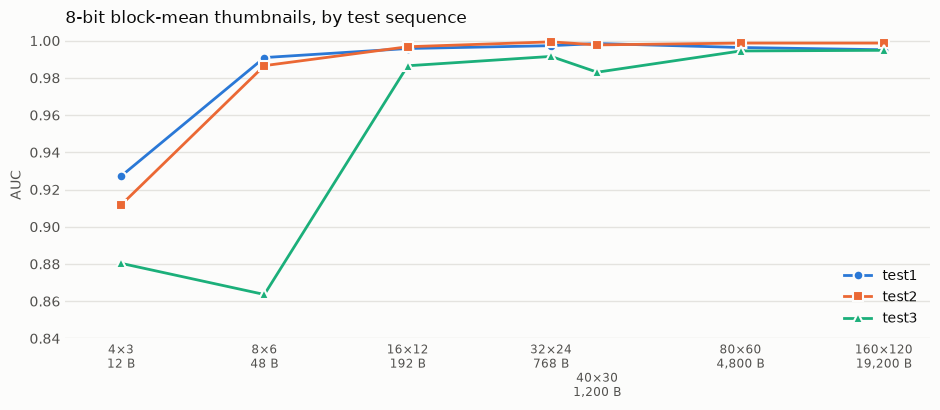

In [6]:
d = df[(df.method == 'mean') & (df.bits == 8)].sort_values('bytes')
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for name, color, marker in zip(TEST, [BLUE, ORANGE, AQUA], 'os^'):
    ax.plot(d.bytes, d[name], lw=2, marker=marker, ms=7, color=color, mec=SURFACE, mew=1.5, label=name)
ax.set_xscale('log')
ax.set_xticks(d.bytes, [('\n\n' if s == '40x30' else '') + f'{x_(s)}\n{b:,} B' for s, b in zip(d['size'], d.bytes)],
              fontsize=8.5)
ax.minorticks_off(); ax.set_xlim(7, 30000); ax.set_ylim(0.84, 1.005)
ax.set_ylabel('AUC'); ax.set_title('8-bit block-mean thumbnails, by test sequence', fontsize=12)
ax.grid(axis='y', color=GRID, lw=1); ax.set_axisbelow(True); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

**Per sequence.** `test1` and `test2` stay at 0.99 down to 48 bytes; `test3` falls to 0.86 there and is the lowest at every size from 16×12 down. In `test3` the person is at times at the bottom edge of the frame (row 4 of the example grid), which may be part of the reason; that is not checked here. The 8×6 point for `test3` is lower than its 4×3 point, which a single training seed cannot distinguish from noise: the per-sequence numbers rest on 140–350 frames each. In the table, the subsample row for 4×3 has AUC 0.29 on `test2`, i.e. worse than chance: twelve single pixels are not a stable input.


## 5. Same payload: more pixels or more bits?

Several payload sizes can be reached two ways. Each row pair below spends the same number of bytes.

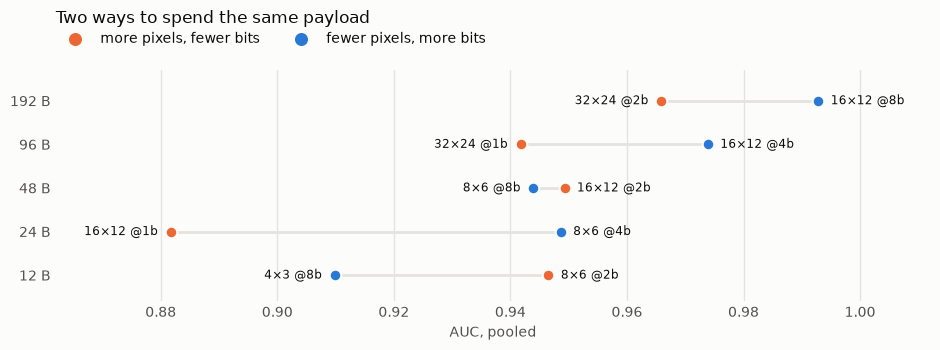

In [8]:
same = df[(df.method == 'mean') & df.bytes.isin(df.bytes[(df.method == 'mean')][df.bytes[(df.method == 'mean')].duplicated()])]
same = same.sort_values(['bytes', 'bits'])
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ypos, yl = 0, []
for nbytes, g in same.groupby('bytes'):
    ax.plot(g.pooled, [ypos] * len(g), color=GRID, lw=2, zorder=1)
    for r in g.itertuples():
        few = r.bits == g.bits.min()
        ax.scatter(r.pooled, ypos, s=70, color=ORANGE if few else BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=2)
        left = r.pooled == g.pooled.min()
        ax.annotate(f'{x_(r.size)} @{r.bits}b', (r.pooled, ypos), (-9 if left else 9, 0), textcoords='offset points',
                    ha='right' if left else 'left', va='center', fontsize=8.5, color=INK)
    yl.append(f'{nbytes} B'); ypos += 1
ax.scatter([], [], s=70, color=ORANGE, label='more pixels, fewer bits')
ax.scatter([], [], s=70, color=BLUE, label='fewer pixels, more bits')
ax.set_yticks(range(len(yl)), yl); ax.set_ylim(-0.6, len(yl) - 0.3); ax.set_xlim(0.862, 1.012)
ax.set_xlabel('AUC, pooled'); ax.set_title('Two ways to spend the same payload', fontsize=12)
ax.grid(axis='x', color=GRID, lw=1); ax.set_axisbelow(True); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.08), ncol=2, borderaxespad=0)
ax.set_title('Two ways to spend the same payload', fontsize=12, pad=34)
plt.tight_layout(); plt.show()

**More pixels or more bits?** There is no single rule. Going from 8 bits to 2 bits per pixel in exchange for four times the pixels is a win at 12 bytes and a tie at 48, but a loss at 192 bytes, where 16×12 at 8 bits is already at the ceiling. Every pair in which one side is a 1-bit code is won by the other side, by 0.03 to 0.07. A workable summary for choosing payloads: stay at 2 bits or more, and prefer resolution until about 16×12.


## 6. How well separated are the scores?

AUC summarises ranking. The histograms show the decoder's raw scores (logits) for frames labelled *person* and *empty*: the less the two overlap, the easier it is to pick a threshold, and the more room a progressive scheme has to stop early on confident frames.

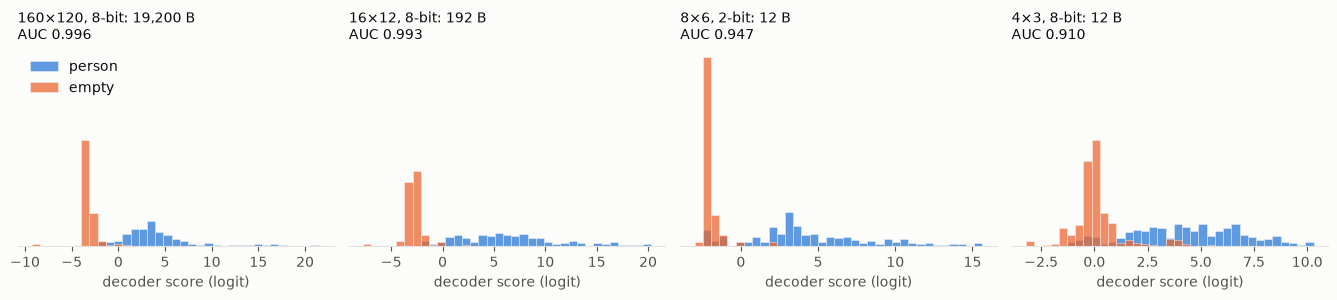

In [9]:
SHOW = [('160x120', 8, 'mean'), ('16x12', 8, 'mean'), ('8x6', 2, 'mean'), ('4x3', 8, 'mean')]
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.1), sharey=True)
for ax, k in zip(axes, SHOW):
    q = Q[k]
    lo, hi = np.percentile(q.score, [0.5, 99.5])
    bins = np.linspace(lo, hi, 36)
    for lab, color, name in [(1, BLUE, 'person'), (0, ORANGE, 'empty')]:
        ax.hist(q.score[q.label == lab].clip(lo, hi), bins, density=True, color=color, alpha=0.75, label=name,
                edgecolor=SURFACE, linewidth=0.4)
    r = df[(df['size'] == k[0]) & (df.bits == k[1]) & (df.method == k[2])].iloc[0]
    ax.set_title(f'{x_(k[0])}, {k[1]}-bit: {r.bytes:,} B\nAUC {r.pooled:.3f}')
    ax.set_xlabel('decoder score (logit)'); ax.set_yticks([])
    for s in ('top', 'right', 'left'):
        ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.show()

**Separation.** At 160×120 and 16×12 the *empty* scores form a narrow spike and the *person* scores spread out well to the right of it, with a small overlap. At 8×6 with 2 bits the empty spike is narrower still: with so few gray levels, the empty room produces the identical payload again and again, so the decoder outputs the identical score. Some *person* frames sit inside that spike (the darker bar at its base), and section 8 shows which. At 4×3 the two classes overlap around zero.

The decoder's zero is not a tuned threshold, but as a rough guide, thresholding at 0 gives accuracy 0.94 at 160×120 and 16×12, 0.89 at 8×6 with 2 bits, and 0.81 at 4×3.


## 7. Scores over time

The simulator replays frames in time order, so each sequence gives a score trace. Shaded spans are frames labelled *person*. This view shows *when* the small payloads go wrong, which matters for anything temporal (filtering, sending only on change).

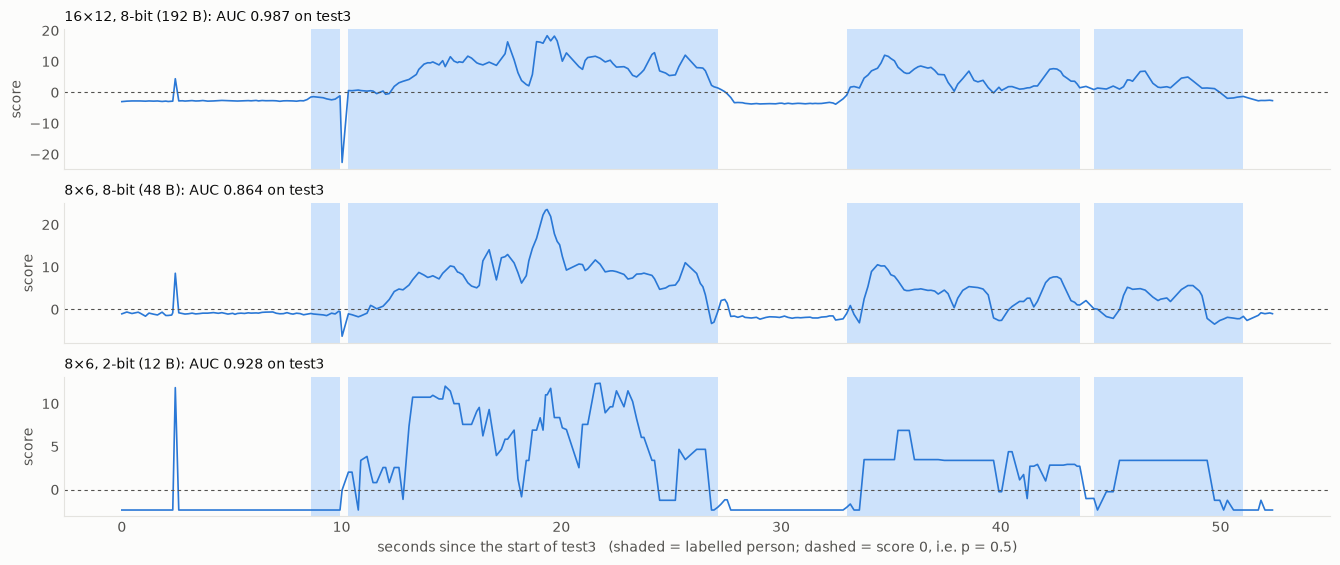

In [10]:
def timeline(seq, keys, colors):
    fig, axes = plt.subplots(len(keys), 1, figsize=(13.5, 1.75 * len(keys) + 0.5), sharex=True)
    for ax, k, color in zip(axes, keys, colors):
        q = Q[k][Q[k].seq == seq]
        t = q.t.values - q.t.values[0]
        lab = q.label.values.astype(bool)
        edges = np.flatnonzero(np.diff(np.r_[0, lab, 0]))
        for a, b in zip(edges[::2], edges[1::2]):
            ax.axvspan(t[a], t[b - 1], color='#cde2fb', lw=0)
        ax.plot(t, q.score, color=color, lw=1.2)
        ax.axhline(0, color=MUTED, lw=0.8, ls=(0, (3, 3)))
        r = df[(df['size'] == k[0]) & (df.bits == k[1]) & (df.method == k[2])].iloc[0]
        ax.set_title(f'{x_(k[0])}, {k[1]}-bit ({r.bytes:,} B): AUC {r[seq]:.3f} on {seq}')
        ax.set_ylabel('score'); ax.tick_params(length=0)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
    axes[-1].set_xlabel(f'seconds since the start of {seq}   (shaded = labelled person; dashed = score 0, i.e. p = 0.5)')
    plt.tight_layout(); plt.show()

timeline('test3', [('16x12', 8, 'mean'), ('8x6', 8, 'mean'), ('8x6', 2, 'mean')], [BLUE, BLUE, BLUE])

**What the traces show.**
* The scores follow the labels closely at 16×12, and errors are not scattered at random: they cluster at the start and end of each visit, when the person is entering or leaving at the edge of the frame. The first few labelled-person frames (8.6–10 s) score as empty at all three sizes.
* Two single-frame excursions appear at every size: a spike at 2.4 s (frame 14) and a dip at 10.0 s (frame 59, most visible at 16×12). Both are mildly corrupted frames, 12 and 5 gray levels darker than the sequence median, which is under the 15-level threshold of the corrupted-frame flag. Both are labelled empty, and frame 59 sits in the middle of a visit. The flag needs to be stricter, or to look at something other than the mean.
* At 8×6 with 2 bits the trace is flat at one value whenever the room is empty, and moves in steps: the payload only changes when a cell crosses a quantisation level. A tag could detect "same payload as last time" with a 12-byte comparison and not transmit at all.
* Because errors are short and sit at transitions, a filter over time on the server should remove many of them. That is not tested here.


## 8. The most confident mistakes

For the one-EPC configuration (8×6 at 2 bits), the frames the decoder got most wrong: *empty*-labelled frames with the highest scores, and *person*-labelled frames with the lowest. Top row of each pair: the 160×120 frame. Bottom row: the 12 bytes the server received.

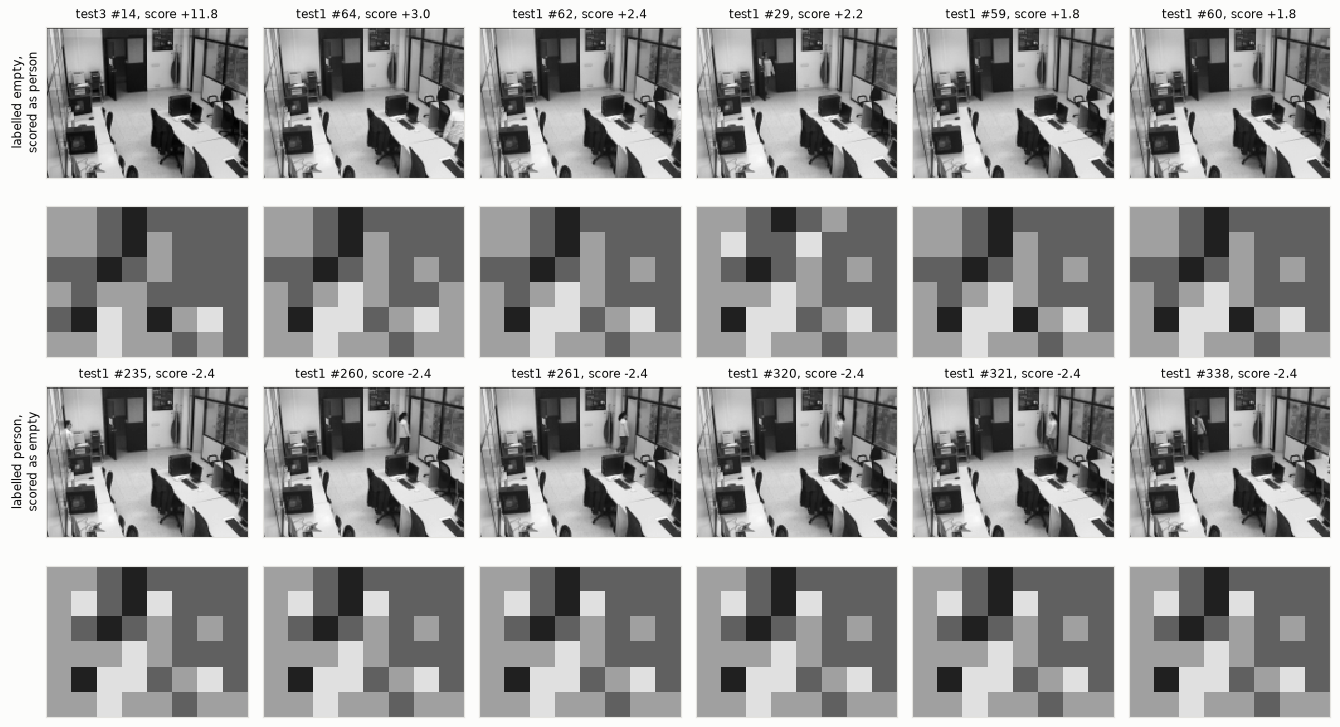

In [11]:
def worst(k, n=6):
    q = Q[k]
    w, h = map(int, k[0].split('x'))
    picks = [('labelled empty, scored as person', q[q.label == 0].nlargest(n, 'score')),
             ('labelled person, scored as empty', q[q.label == 1].nsmallest(n, 'score'))]
    fig, axes = plt.subplots(4, n, figsize=(13.5, 7.4))
    for g, (title, rows_) in enumerate(picks):
        for c, r in enumerate(rows_.itertuples()):
            frame = frames[r.seq]['X'][r.idx]
            for j, img in enumerate([frame / 255, received(frame, w, h, k[1], k[2])[0]]):
                ax = axes[2 * g + j, c]
                ax.imshow(img, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
                ax.set_xticks([]); ax.set_yticks([])
                if j == 0:
                    ax.set_title(f'{r.seq} #{r.idx}, score {r.score:+.1f}', fontsize=8.5, loc='center')
            if c == 0:
                axes[2 * g, 0].set_ylabel(title.replace(', ', ',\n'), fontsize=8.5, color=INK)
    plt.tight_layout(); plt.show()

worst(('8x6', 2, 'mean'))

**What the mistakes are.**
* **Labelled person, scored as empty** (bottom half): all six are a person standing far from the camera, by the door or the window, where they cover a small part of one cell. All six get exactly the same score, −2.4, which is the empty-room score: their 12-byte payload is identical to an empty-room payload. Across the test set, 764 frames produce only 206 distinct payloads, and the single most common payload is shared by 174 empty frames and 29 person frames. Counting every shared payload, 61 frames (8%) are on the minority side of a payload that both classes produce, and no decoder can get those right. At one EPC the errors are a property of the code.
* **Labelled empty, scored as person** (top half): the first is the corrupted frame from section 7. `test1` #29 shows a person in the doorway and is labelled empty, so the decoder is right and the label is wrong. In the rest the door appears to be open or moving, which changes the same cells a person at the door would.
* Where the uniform grid fails is therefore specific: the far end of the room. A code that spends its cells and thresholds there, rather than evenly, is the natural next thing to try at this payload size.


## 9. What each configuration costs the tag

The simulator's ledger counts, per query. `EPCs` includes the chunk index that a multi-EPC payload needs. `mcu_ops` and `ram_bytes` are rough counts, not measurements: block averaging adds every pixel into one row of accumulators, and the payload buffer is held until it is sent.

In [12]:
cost = df[['size', 'bits', 'method', 'bytes', 'EPCs', 'mcu_ops', 'ram_bytes', 'pooled']].rename(columns={'pooled': 'AUC pooled'})
cost.style.format({'AUC pooled': '{:.3f}'} | {c: '{:,}' for c in ['bytes', 'EPCs', 'mcu_ops', 'ram_bytes']}) \
    .bar(subset=['EPCs'], color='#cde2fb').hide(axis='index')

size,bits,method,bytes,EPCs,mcu_ops,ram_bytes,AUC pooled
160x120,8,mean,"19,200","1,920","57,600","19,520",0.996
80x60,8,mean,"4,800",480,"28,800","4,960",0.993
40x30,8,mean,"1,200",110,"21,600","1,280",0.990
32x24,8,mean,768,70,"20,736",832,0.992
32x24,8,subsample,768,70,768,768,0.979
32x24,4,mean,384,35,"20,736",448,0.981
16x12,8,mean,192,18,"19,584",224,0.993
32x24,2,mean,192,18,"20,736",256,0.966
16x12,8,subsample,192,18,192,192,0.981
16x12,4,mean,96,9,"19,584",128,0.974


**Cost.** The uncompressed frame needs 1,920 EPC reads per query; 16×12 needs 18, and everything at 12 bytes or below fits in one. Block averaging costs about one addition per pixel whatever the output size, and its working memory is one row of accumulators plus the payload, which fits in the MSP430FR5969's 2 KB of SRAM up to 40×30 (1,280 bytes); 80×60 and the full frame would have to go through FRAM. Subsampling costs almost no computation but, as shown above, gives a worse payload. These are counts; `semwisp/cost.py` cannot turn them into energy until its constants are measured.


## What this suggests next

* **Room-fitted codes at one EPC.** Choose cells and thresholds for this room instead of a uniform grid (sections 5 and 8). This is the smallest version of "the server sends the tag better instructions".
* **Progressive queries.** Empty-room frames are scored confidently from 12 bytes (section 6); only the uncertain ones need a second, larger request.
* **Time.** Errors sit at the edges of visits and in single glitched frames (section 7), and an unchanged payload need not be sent.
* **Fix the corrupted-frame flag** before the next experiment, since two frames it misses are the largest errors here.
* **Robustness, not yet run:** sensor noise (`--read-noise`), EPC loss (`--p-loss`), more than one training seed, and a decoder trained on much less labelled data.
